# Erythroid

The mouse erythroid differentiation dataset used by Petrović et al. (2025) consists of 9,815 cells along the erythroid developmental trajectory. For pseudotime hold-out, the cells are partitioned into three pseudotime partitions with the intermediate population withheld during training, and we evaluate in the two-dimensional embedding and in $d \in \{20, 50\}$ dimensional representations. For experimental-time hold-out, E7.0–E7.75 define the source, E8.5 the target, and E8.0/E8.25 are withheld. Under pseudotime hold-out, hyperparameters are tuned on disjoint validation subsets; under experimental-time hold-out, they are the log-median of the tuned Pancreas and iTracer points (Erythroid's own pseudotime tuning is excluded) and are used without retuning.

Reproduces Table 7 and the Erythroid columns of Table 1.

In [1]:
import pathlib
import sys

ROOT = next(p for p in (pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents)
            if (p / "ffm").is_dir() and (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT))

from scripts.erythroid import paper

paper.ensure()

## Dataset

The 9,815 cells in the two-dimensional embedding, by lineage stage and by the three pseudotime partitions. The intermediate partition is withheld during training; 2,941 of its 3,271 cells are scored and the remaining 330 are used for tuning.

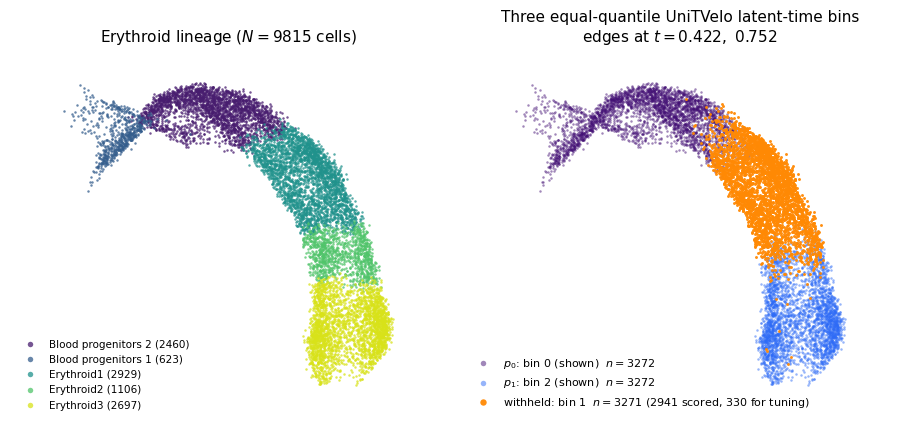

In [2]:
paper.figure_dataset()

## Midpoint and endpoint $W_2$

Pseudotime: midpoint $W_2$ is the Table 7 value ($t = 1/2$ against the 2,941 scored withheld cells) and endpoint $W_2$ compares $t = 1$ of the same runs with the 3,272 cells of the last partition. Real-time: midpoint $W_2$ is the Table 7 value ($t = 1/2$ against the pooled E8.0 and E8.25 cells, 400 points per side) and endpoint $W_2$ compares $t = 1$ with the E8.5 cells (800 points per side, mean of five draws) in separate runs with the same configuration and seed. The sampling floor is $W_2$ between two halves of the pooled withheld cells (800 points per side, mean of five draws), so it is not size-matched to the 400-point midpoint values; no floor is recorded for the pseudotime runs or for the real-time endpoint.

In [3]:
paper.mid_end()

mid W2          end W2
                   Method                                                     
Pseudotime, d = 2  OT-CFM                        0.679 ± 0.009   0.177 ± 0.004
                   MFM / LAND                    0.293 ± 0.010   0.221 ± 0.018
                   Curly-FM                      0.226 ± 0.008   0.189 ± 0.006
                   FFM (ours)                    0.289 ± 0.027   0.217 ± 0.010
                   FFM (ours), with noise        0.286 ± 0.025   0.213 ± 0.026
Pseudotime, d = 20 OT-CFM                        6.258 ± 0.066   3.765 ± 0.073
                   MFM / LAND                    4.856 ± 0.054   4.871 ± 0.148
                   Curly-FM                      6.271 ± 0.047   3.634 ± 0.020
                   FFM (ours)                    4.778 ± 0.013   3.794 ± 0.047
                   FFM (ours), with noise        4.833 ± 0.024   3.586 ± 0.021
Pseudotime, d = 50 OT-CFM                        7.975 ± 0.016   5.768 ± 0.038
                   MFM / LAND                    6.819 ± 0.058   6.450 ± 0.102
                   Curly-FM                      7.861 ± 0.048   5.632 ± 0.011
                   FFM (ours)                    6.908 ± 0.026   5.931 ± 0.046
                   FFM (ours), with noise        7.084 ± 0.021   5.696 ± 0.020
Real-time, d = 20  OT-CFM                        6.898 ± 0.177   4.349 ± 0.153
                   MFM / LAND                    6.085 ± 0.187   9.179 ± 0.897
                   Curly-FM                      9.891 ± 0.496   4.886 ± 0.275
                   FFM (ours)                    6.588 ± 0.309   4.795 ± 0.665
                   FFM (ours), with noise        6.744 ± 0.566   4.662 ± 0.690
                   FFM, expression               5.755 ± 0.172   4.827 ± 0.179
                   FFM, expression + noise       5.889 ± 0.217   4.391 ± 0.177
                   sampling floor (800 points)           4.080               –
Real-time, d = 50  OT-CFM                        8.744 ± 0.208   7.060 ± 0.193
                   MFM / LAND                    9.051 ± 0.324  12.486 ± 0.662
                   Curly-FM                     11.465 ± 0.402   7.244 ± 0.029
                   FFM (ours)                    8.181 ± 0.180   7.690 ± 0.425
                   FFM (ours), with noise        8.321 ± 0.265   8.135 ± 1.117
                   FFM, expression               7.886 ± 0.086   7.472 ± 0.173
                   FFM, expression + noise       7.992 ± 0.157   7.892 ± 0.487
                   sampling floor (800 points)           5.973               –

## Learned trajectories ($d = 2$)

Seed-0 trajectories of each method under pseudotime hold-out in the two-dimensional embedding; the withheld partition is scored at $t = 1/2$.

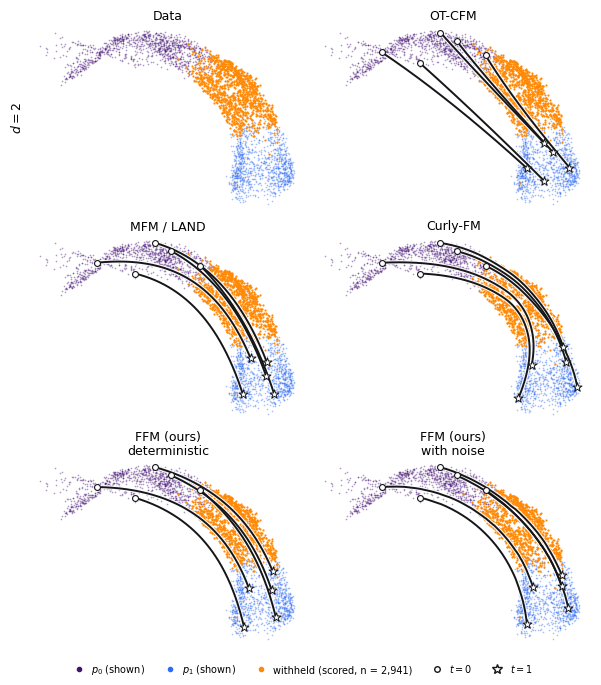

In [4]:
paper.figure_paths()

## Intermediate-state interpolation (Table 1, Erythroid)

Midpoint $W_2$ under pseudotime and real-time hold-out; FFM uses a velocity-derived kernel. Mean ± population SD over five seeds.

In [5]:
paper.table1()

Pseudotime       Real-time
                                   Erythroid       Erythroid
       Method                                               
d = 20 OT-CFM                  6.258 ± 0.066   6.898 ± 0.177
       MFM / LAND              4.856 ± 0.054   6.085 ± 0.187
       Curly-FM                6.271 ± 0.047   9.891 ± 0.496
       FFM (ours)              4.778 ± 0.013   6.588 ± 0.309
       FFM (ours), with noise  4.833 ± 0.024   6.744 ± 0.566
d = 50 OT-CFM                  7.975 ± 0.016   8.744 ± 0.208
       MFM / LAND              6.819 ± 0.058   9.051 ± 0.324
       Curly-FM                7.861 ± 0.048  11.465 ± 0.402
       FFM (ours)              6.908 ± 0.026   8.181 ± 0.180
       FFM (ours), with noise  7.084 ± 0.021   8.321 ± 0.265

## Pseudotime hold-out (Table 7, top)

Published baseline $W_1$ values are compared with our leakage-free reproduction. The quantity reported as $W_2$ in Petrović et al. (2025) corresponds to $W_1$ due to a bug in their code; we additionally report the true $W_2$. All pseudotime runs, FFM included, use the published Curly-FM training budget instead of the protocol of App. C: three hidden layers of width 64 ($d = 2$) or 256 ($d \in \{20, 50\}$), learning rate $10^{-4}$, batch size 256 and, where applicable, 2,000 ($d = 2$) or 3,000 ($d \in \{20, 50\}$) geodesic iterations followed by 3,000 flow-matching or bridge iterations.

In [6]:
paper.table7_pseudotime()

Published W1  Reproduced W1  \
                   Method                                                 
Pseudotime, d = 2  OT-CFM                  0.646 ± 0.006  0.645 ± 0.009   
                   MFM / LAND              0.269 ± 0.004  0.279 ± 0.011   
                   Curly-FM                0.369 ± 0.090  0.197 ± 0.008   
                   FFM (ours)                          –  0.245 ± 0.034   
                   FFM (ours), with noise              –  0.243 ± 0.031   
Pseudotime, d = 20 OT-CFM                  6.103 ± 0.074  6.104 ± 0.064   
                   MFM / LAND              4.855 ± 0.052  4.760 ± 0.056   
                   Curly-FM                6.124 ± 0.027  6.110 ± 0.043   
                   FFM (ours)                          –  4.681 ± 0.011   
                   FFM (ours), with noise              –  4.742 ± 0.024   
Pseudotime, d = 50 OT-CFM                  7.969 ± 0.029  7.840 ± 0.016   
                   MFM / LAND              6.727 ± 0.022  6.698 ± 0.053   
                   Curly-FM                7.729 ± 0.046  7.731 ± 0.045   
                   FFM (ours)                          –  6.811 ± 0.022   
                   FFM (ours), with noise              –  7.018 ± 0.022   

                                           Reproduced W2  
                   Method                                 
Pseudotime, d = 2  OT-CFM                  0.679 ± 0.009  
                   MFM / LAND              0.293 ± 0.010  
                   Curly-FM                0.226 ± 0.008  
                   FFM (ours)              0.289 ± 0.027  
                   FFM (ours), with noise  0.286 ± 0.025  
Pseudotime, d = 20 OT-CFM                  6.258 ± 0.066  
                   MFM / LAND              4.856 ± 0.054  
                   Curly-FM                6.271 ± 0.047  
                   FFM (ours)              4.778 ± 0.013  
                   FFM (ours), with noise  4.833 ± 0.024  
Pseudotime, d = 50 OT-CFM                  7.975 ± 0.016  
                   MFM / LAND              6.819 ± 0.058  
                   Curly-FM                7.861 ± 0.048  
                   FFM (ours)              6.908 ± 0.026  
                   FFM (ours), with noise  7.084 ± 0.021

## Experimental-time hold-out (Table 7, bottom)

E7.0–E7.75 is the source and E8.5 the target, with E8.0 and E8.25 withheld. The temporal mean averages 11 separately computed $W_2$ distances over $[1/3, 2/3]$; FFM uses a velocity-derived kernel unless otherwise indicated. Curly-FM uses $\alpha = 1$ with the velocity rescaled to the median source–target displacement, since the transferred $\alpha$ diverges at $d = 20$.

In [7]:
paper.table7_realtime()

d = 20                         d = 50  \
                              W2 (1/2)  W2 [1/3, 2/3]        W2 (1/2)   
Method                                                                  
OT-CFM                   6.898 ± 0.177  7.151 ± 0.176   8.744 ± 0.208   
MFM / LAND               6.085 ± 0.187  6.657 ± 0.079   9.051 ± 0.324   
Curly-FM                 9.891 ± 0.496  9.862 ± 0.489  11.465 ± 0.402   
FFM (ours)               6.588 ± 0.309  6.769 ± 0.279   8.181 ± 0.180   
FFM (ours), with noise   6.744 ± 0.566  6.904 ± 0.529   8.321 ± 0.265   
FFM, expression          5.755 ± 0.172  6.097 ± 0.152   7.886 ± 0.086   
FFM, expression + noise  5.889 ± 0.217  6.215 ± 0.208   7.992 ± 0.157   

                                         
                          W2 [1/3, 2/3]  
Method                                   
OT-CFM                    8.956 ± 0.214  
MFM / LAND                9.068 ± 0.260  
Curly-FM                 11.433 ± 0.394  
FFM (ours)                8.393 ± 0.180  
FFM (ours), with noise    8.524 ± 0.266  
FFM, expression           8.136 ± 0.095  
FFM, expression + noise   8.234 ± 0.155